# Composition of protein expression subsystems
### Ayush Pandey

Now we consider the design of a regulated protein expression system where a protein $p_1$ represses the transcript of $p_2$, the protein of interest. We specify this design with a requirement $p_2^*\geq15$ nM under low DNA input and $p_2^*\leq5$ nM under high DNA input.

To meet these requirements, we model two transcription and translation modules with DNA inputs $d_1,d_2$. Each module has dynamics
$$\dot m_i=r_i-\delta_{m,i}m_i,\qquad
\dot p_i=k_{\mathrm{tl},i}m_i-\delta_{p,i}p_i,$$
where $m_i,p_i$ are transcript and protein concentrations, $k_{\mathrm{tl},i}$ is the translation coefficient, and $\delta_{m,i},\delta_{p,i}>0$ are degradation coefficients. The transcription rates are
$$r_1=k_1d_1,\qquad r_2=\frac{k_2d_2}{1+(p_1/K)^n}.$$
At equilibrium, $p_i^*=k_{\mathrm{tl},i}r_i/(\delta_{m,i}\delta_{p,i})$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from pacti.contracts import PolyhedralIoContract
from scipy.integrate import solve_ivp

from biospeak import (
    coefficient_bounds,
    hill_contracts,
    hill_limits,
    refines,
    to_contract,
)
from biospeak.contracts import interval, row

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42})

## Component contracts and composition

With $d_2=1$ nM, we choose the DNA input regions so that the guaranteed range of $p_1^*$ lies within $[1,5]$, $[5,20]$, and $[20,100]$ nM. We compose the constitutive expression contract and the repression contract to eliminate the shared variable $p_1$ and obtain a guarantee on $p_2$.

In [2]:
bounds = {
    "k": (0.9, 1.1),
    "K": (9.0, 11.0),
    "ktl": (0.45, 0.55),
    "delta_m": (0.18, 0.22),
    "delta_p": (0.09, 0.11),
}
cmin, cmax = coefficient_bounds(bounds)
entries = hill_contracts(
    4,
    False,
    bounds["K"],
    (cmin, cmax),
    input_name="z_p1",
    output_name="z_p2",
    dna_name="z_d2",
)
operating_intervals = [
    (lo / cmin, hi / cmax) for lo, hi in [(1, 5), (5, 20), (20, 100)]
]
compositions, results = [], []
for entry, (dlo, dhi) in zip(entries, operating_intervals):
    upstream = PolyhedralIoContract.from_dict(
        dict(
            input_vars=["z_d1"],
            output_vars=["z_p1"],
            assumptions=interval("z_d1", np.log(dlo), np.log(dhi)),
            guarantees=[
                row({"z_d1": 1, "z_p1": -1}, -np.log(cmin)),
                row({"z_d1": -1, "z_p1": 1}, np.log(cmax)),
            ],
        ),
        simplify=False,
    )
    fixed_dna = interval("z_d2", 0.0, 0.0)
    composed = upstream.compose(to_contract(entry, fixed_dna), simplify=False)
    lower, upper = np.exp(composed.get_variable_bounds("z_p2"))
    external = upstream.to_machine_dict()["assumptions"] + fixed_dna
    specifications = [
        PolyhedralIoContract.from_dict(
            dict(
                input_vars=["z_d1", "z_d2"],
                output_vars=["z_p2"],
                assumptions=external,
                guarantees=[row({"z_p2": sign}, sign * np.log(threshold))],
            ),
            simplify=False,
        )
        for sign, threshold in [(-1, 15), (1, 5)]
    ]
    on, off = [refines(composed, spec) for spec in specifications]
    compositions.append(composed)
    results.append(
        dict(
            region=entry["region"],
            DNA_lower=dlo,
            DNA_upper=dhi,
            protein_lower=lower,
            protein_upper=upper,
            ON=on,
            OFF=off,
        )
    )
pd.DataFrame(results)

,region,DNA_lower,DNA_upper,protein_lower,protein_upper,ON,OFF
0,Low,0.059753,0.133884,15.279969,37.343128,True,False
1,Transition,0.298765,0.535537,0.659229,35.816723,False,False
2,High,1.195062,2.677686,0.001098,3.130869,False,True


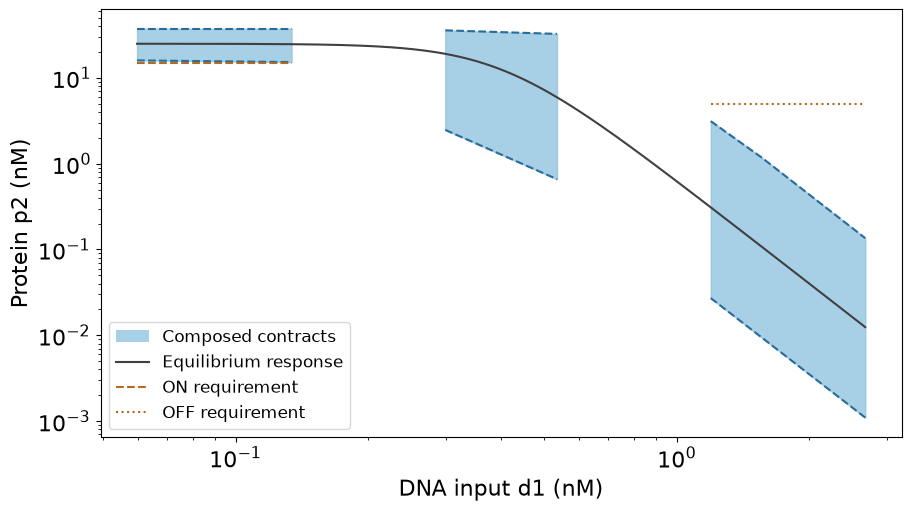

In [3]:
assert results[0]["ON"] and results[2]["OFF"]
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for entry, (dlo, dhi) in zip(entries, operating_intervals):
    d1 = np.geomspace(dlo, dhi, 150)
    lower = hill_limits(entry, cmax * d1)[0]
    upper = hill_limits(entry, cmin * d1)[1]
    ax.fill_between(d1, lower, upper, color="#91c3df", alpha=0.8)
    ax.plot(d1, lower, "--", color="#286c99")
    ax.plot(d1, upper, "--", color="#286c99")
d1 = np.geomspace(operating_intervals[0][0], operating_intervals[-1][1], 250)
p1 = 25 * d1
p2 = 25 / (1 + (p1 / 10) ** 4)
ax.plot(d1, p2, color="0.25", label="Equilibrium response")
ax.plot(operating_intervals[0], [15, 15], "--", color="#b46b20", label="ON requirement")
ax.plot(operating_intervals[2], [5, 5], ":", color="#b46b20", label="OFF requirement")
ax.set(xscale="log", yscale="log", xlabel="DNA input d1 (nM)", ylabel="Protein p2 (nM)")
handles, labels = ax.get_legend_handles_labels()
handles.insert(0, Patch(facecolor="#91c3df", alpha=0.8))
labels.insert(0, "Composed contracts")
ax.legend(handles, labels, fontsize=12)
plt.show()

## Transcription and translation dynamics

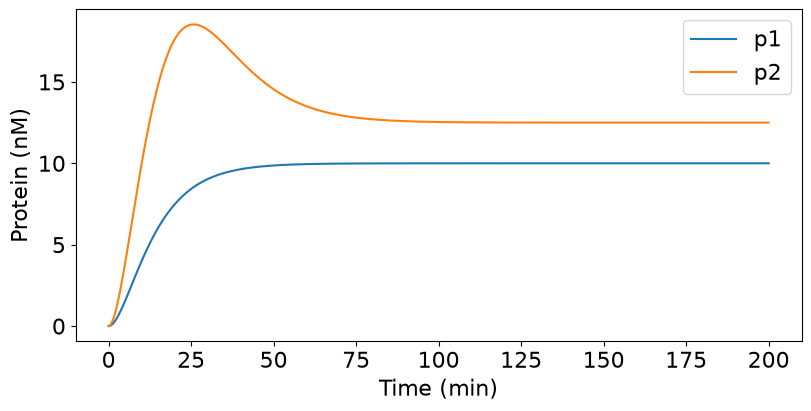

In [4]:
d1, d2 = 0.4, 1.0


def expression_dynamics(t, state):
    m1, p1, m2, p2 = state
    return [
        d1 - 0.2 * m1,
        0.5 * m1 - 0.1 * p1,
        d2 / (1 + (p1 / 10) ** 4) - 0.2 * m2,
        0.5 * m2 - 0.1 * p2,
    ]


solution = solve_ivp(
    expression_dynamics,
    (0, 200),
    [0, 0, 0, 0],
    t_eval=np.linspace(0, 200, 400),
    rtol=1e-9,
    atol=1e-11,
)
assert np.allclose(solution.y[[1, 3], -1], [10, 12.5], rtol=1e-6)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(solution.t, solution.y[1], label="p1")
ax.plot(solution.t, solution.y[3], label="p2")
ax.set(xlabel="Time (min)", ylabel="Protein (nM)")
ax.legend()
plt.show()